In [1]:
import pandas as pd
from scipy.sparse import load_npz

X_train = load_npz("../data/X_train_tfidf.npz")
X_test = load_npz("../data/X_test_tfidf.npz")
y_train = pd.read_csv("../data/y_train.csv").iloc[:, 0]
y_test = pd.read_csv("../data/y_test.csv").iloc[:, 0]
X_train_bow = load_npz("../data/X_train_bow.npz")
X_test_bow = load_npz("../data/X_test_bow.npz")

print(X_train.shape, X_test.shape, len(y_train), len(y_test))

(40000, 20000) (10000, 20000) 40000 10000


In [2]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

for name, Xtrain, Xtest in [("TF-IDF", X_train, X_test), ("BoW", X_train_bow, X_test_bow)]:
    nb = MultinomialNB()
    nb.fit(Xtrain, y_train)
    preds = nb.predict(Xtest)
    print(f"--- Naive Bayes on {name} ---")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print(classification_report(y_test, preds, digits=3))

--- Naive Bayes on TF-IDF ---
Accuracy: 0.7908
Macro F1: 0.3442
              precision    recall  f1-score   support

    Negative      0.895     0.082     0.151      1446
     Neutral      0.000     0.000     0.000       752
    Positive      0.790     0.998     0.882      7802

    accuracy                          0.791     10000
   macro avg      0.561     0.360     0.344     10000
weighted avg      0.745     0.791     0.710     10000

--- Naive Bayes on BoW ---
Accuracy: 0.8262
Macro F1: 0.5963
              precision    recall  f1-score   support

    Negative      0.621     0.620     0.620      1446
     Neutral      0.344     0.211     0.262       752
    Positive      0.890     0.924     0.907      7802

    accuracy                          0.826     10000
   macro avg      0.618     0.585     0.596     10000
weighted avg      0.810     0.826     0.817     10000



Baseline accuracy: 0.7802
Baseline macro F1: 0.2922


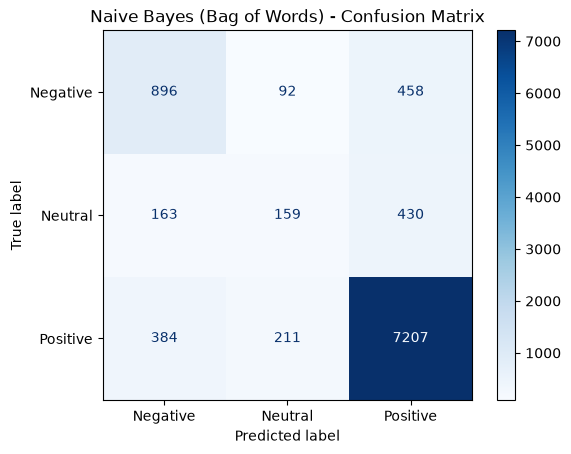

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

base = DummyClassifier(strategy="most_frequent").fit(X_train_bow, y_train)
base_preds = base.predict(X_test_bow)
print("Baseline accuracy:", round(accuracy_score(y_test, base_preds), 4))
print("Baseline macro F1:", round(f1_score(y_test, base_preds, average="macro"), 4))

nb_bow = MultinomialNB().fit(X_train_bow, y_train)
bow_preds = nb_bow.predict(X_test_bow)

os.makedirs("../report/figures", exist_ok=True)
ConfusionMatrixDisplay.from_predictions(y_test, bow_preds, cmap="Blues")
plt.title("Naive Bayes (Bag of Words) - Confusion Matrix")
plt.savefig("../report/figures/nb_bow_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
import joblib, numpy as np

vec = joblib.load("../data/vectorizers.joblib")
print(type(vec))
if isinstance(vec, dict):
    print(vec.keys())
    bow_vec = [v for k, v in vec.items() if "bow" in k.lower() or "count" in k.lower()][0]
else:
    bow_vec = vec
words = bow_vec.get_feature_names_out()

classes = list(nb_bow.classes_)
pos, neg = classes.index("Positive"), classes.index("Negative")
ratio = nb_bow.feature_log_prob_[pos] - nb_bow.feature_log_prob_[neg]

top_pos = words[np.argsort(ratio)[-10:][::-1]]
top_neg = words[np.argsort(ratio)[:10]]
print("Top positive:", list(top_pos))
print("Top negative:", list(top_neg))

os.makedirs("../results", exist_ok=True)
pd.DataFrame({"top_positive": top_pos, "top_negative": top_neg}).to_csv("../results/top_features.csv", index=False)

wrong = pd.DataFrame({"true": y_test.values, "predicted": bow_preds})
wrong = wrong[wrong["true"] != wrong["predicted"]]
wrong.to_csv("../results/misclassified.csv")
print(len(wrong), "misclassified reviews saved")

<class 'dict'>
dict_keys(['bow_vectorizer', 'tfidf_vectorizer'])
Top positive: ['soothing', 'hawaii', 'pleasantly', 'matcha', 'schedule', 'pb2', 'hooked', 'relax', 'calm', 'overweight']
Top negative: ['housemate', 'unmeasured', 'buffoon', 'parsing', 'vile', 'deliberately', 'ripoff', 'kaboodle', 'slaughterhouse', 'trashing']
1738 misclassified reviews saved


c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: Inconsist

In [5]:
counts = np.asarray(X_train_bow.sum(axis=0)).ravel()
common = counts >= 250

r = np.where(common, ratio, np.nan)
order = np.argsort(r)
valid = order[~np.isnan(r[order])]

top_pos = words[valid[-10:][::-1]]
top_neg = words[valid[:10]]
print("Top positive:", list(top_pos))
print("Top negative:", list(top_neg))

pd.DataFrame({"top_positive": top_pos, "top_negative": top_neg}).to_csv("../results/top_features.csv", index=False)

Top positive: ['matcha', 'hooked', 'beat', 'yum', 'delicious', 'yummy', 'refreshing', 'perfect', 'highly', 'keeps']
Top negative: ['worst', 'return', 'awful', 'horrible', 'terrible', 'china', 'nasty', 'stale', 'waste', 'description']


In [6]:
os.makedirs("../models", exist_ok=True)
joblib.dump(nb_bow, "../models/nb_bow_model.joblib")
print("Saved model")

Saved model
